# Bayesian Inference for Online Shopper Conversion: Updating Beliefs as New Data Arrives

**Course:** AIT 530

**Assignment:** Bayesian Statistics — Prior, Likelihood, and Posterior

**By:** Yashu Lanki

**Video Presentation:** [https://youtu.be/L7VuaaJzySg](https://youtu.be/L7VuaaJzySg)

## Table of Contents

1. Introduction and Objective
2. Data Description
3. Data Preprocessing
4. Analytical Model Description
5. The Architectural Model (Pipeline) Used
6. Model Implementation
7. Assumptions Verification
8. Deployment
9. Execution
10. Results
11. Model Validation
12. Analysis
13. Error Estimation
14. Model Improvement
15. Final Conclusion
16. References

## 1. Introduction and Objective

**The AI problem.** Online stores use AI to predict **user behavior**, especially whether a visitor will **make a purchase**. The most basic quantity behind every purchase-prediction model is the **conversion rate**: the probability *θ* that a session ends in a purchase. Businesses watch it every day, and it changes as new visitors arrive.

**Why Bayesian?** Bayesian statistics treats *θ* as uncertain and describes our belief about it with a probability distribution. It starts with a **prior** belief, combines it with the **likelihood** of the observed data, and produces a **posterior** belief. When new data arrives, today's posterior becomes tomorrow's prior. This is exactly how an adaptive AI system should learn.

**Objectives.**
1. Choose a key variable (whether a session ends in a purchase) and justify a **prior** and a **likelihood** for its conversion rate.
2. Calculate the **posterior** with Bayes' rule, both exactly (conjugate formula) and with a **PyMC** model (MCMC sampling).
3. **Update the model as new data arrives**, month by month and in a simulated stream, and analyze how the posterior changes.
4. **Compare** the Bayesian approach with the frequentist **maximum likelihood estimate (MLE)**, and discuss Bayesian methods in **adaptive learning**.

## 2. Data Description

### 2.1 Kaggle Review

**Notebook reviewed:** *A/B Testing: Frequentist and Bayesian Approaches* by bbergerud on Kaggle (https://www.kaggle.com/code/bbergerud/a-b-testing-frequentist-and-bayesian-approaches). It uses an A/B test dataset of 10,000 website visits. Each row records a user ID, the version of the page the user saw (control or variant), and the revenue from the visit.

**What it implements and how:**
- **Data cleaning:** it removes users who saw both versions and one extreme revenue outlier, so the two groups are comparable.
- **Frequentist analysis:** it checks normality (Shapiro–Wilk and D'Agostino–Pearson tests) and equal variances (Levene test), then uses a Mann–Whitney test because revenue is not normal. It also bootstraps the difference in revenue between the groups.
- **Bayesian analysis with PyMC:** it models the **probability of a purchase** with a Bernoulli likelihood and the **revenue per purchase** with a Normal likelihood. For the priors, it uses truncated Normal distributions centered on values calculated from the data itself. It samples the posterior with MCMC (2 chains of 1,000 draws) and uses ArviZ to plot the traces and the 95% highest-density intervals.
- **Conclusion:** both approaches find no clear difference between the versions, but the Bayesian posterior shows the control group is *more likely than not* to perform slightly better.

**What I adopted:** a **Bernoulli likelihood** for whether a visit ends in a purchase, **PyMC** with MCMC sampling to get the posterior, **ArviZ** diagnostics, a side-by-side **frequentist vs. Bayesian** comparison, and the idea of reporting a **probability** that one group is better (my Section 12.2).

**What I did differently:**
- **Prior choice.** That notebook mentions that a Beta distribution is the usual prior for a probability but uses a truncated Normal centered on the data's own average. Using the same data to set the prior and to update it counts the data twice. I used a **Beta(2, 18)** prior chosen *before* looking at this data, and I checked the effect of the prior with a sensitivity analysis.
- **Exact check of PyMC.** Because the Beta prior is conjugate to the Bernoulli likelihood, I calculated the exact posterior and confirmed that PyMC matches it.
- **Updating over time.** That notebook fits the model once to all the data. I **updated the posterior as new data arrived**, month by month and in a simulated stream, which is what the assignment asks for.
- **Prediction and validation.** I used the posterior to **predict future months** and tested those predictions, which revealed that the conversion rate changes over time. I then improved the model with a forgetting factor.
- **Comparison with MLE.** Instead of hypothesis tests, I compared Bayesian estimates with the **maximum likelihood estimate** directly, including their error and interval coverage on repeated samples.

### 2.2 Selected Dataset and Key Variable

I used the **Online Shoppers Purchasing Intention Dataset** from the **UCI Machine Learning Repository** (Sakar & Kastro, 2018). It contains **12,330 website sessions** from an online store over one year. Each session belongs to a different user, and the data covers ten months (there are no January or April sessions). For each session, it records pages visited, time spent, bounce and exit rates, the month, the visitor type, and whether the session ended in a purchase.

**Key variable: `Revenue`** (True/False): did the session end in a purchase? I chose it because:
- **It is the target of a real AI problem:** predicting purchasing intention, which online stores use to target offers and personalize pages (Sakar et al., 2019).
- **Its parameter is easy to interpret:** the conversion rate *θ* is the single number a business tracks most closely.
- **It has a natural Bayesian structure:** each session is a yes/no outcome, which fits the Beta–Bernoulli model and allows exact posterior formulas to check the PyMC results.
- **The data arrives over time:** the `Month` column lets the model be updated as new months of data become available, which is the core of the assignment.

| Variable | Type | Used for |
|---|---|---|
| `Revenue` | Categorical (True/False) | **Key variable**: purchase or not |
| `Month` | Categorical | Order in which new data arrives (sequential updating) |
| `VisitorType` | Categorical | Comparing new and returning visitors |
| `PageValues` | Numerical | A predictor for the Bayesian vs. MLE regression in Section 14 |

In [1]:
# --- Libraries ---
import numpy as np                 # arrays and random number generation
import pandas as pd                # loading and summarizing the sessions table
import matplotlib.pyplot as plt    # charts
import seaborn as sns              # nicer default chart style
from scipy import stats            # Beta, Binomial, and chi-square distributions
from pathlib import Path           # file path that works on any computer
import pymc as pm                  # Bayesian modeling with MCMC sampling
import arviz as az                 # diagnostics for MCMC results (r-hat, effective sample size)
import statsmodels.api as sm       # frequentist (MLE) logistic regression for comparison
import logging

logging.getLogger("pymc").setLevel(logging.ERROR)   # hide PyMC's routine progress messages
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# --- Load the dataset safely ---
# If the file is missing or unreadable, stop with a clear message instead of a long raw error.
DATA_FILE = Path("shopper_data") / "online_shoppers_intention.csv"
try:
    shop = pd.read_csv(DATA_FILE)
except FileNotFoundError:
    raise FileNotFoundError(
        f"Could not find '{DATA_FILE}'. Make sure the 'shopper_data' folder is next to this notebook "
        "and contains 'online_shoppers_intention.csv' from the UCI repository."
    ) from None
except pd.errors.ParserError as err:
    raise ValueError(f"'{DATA_FILE}' could not be read as a CSV file: {err}") from None

print(f"Sessions: {shop.shape[0]:,}   Columns: {shop.shape[1]}")
shop[["Month", "VisitorType", "PageValues", "BounceRates", "Revenue"]].head()

Sessions: 12,330   Columns: 18


,Month,VisitorType,PageValues,BounceRates,Revenue
0,Feb,Returning_Visitor,0.0000,0.2000,False
1,Feb,Returning_Visitor,0.0000,0.0000,False
2,Feb,Returning_Visitor,0.0000,0.2000,False
3,Feb,Returning_Visitor,0.0000,0.0500,False
4,Feb,Returning_Visitor,0.0000,0.0200,False


## 3. Data Preprocessing

The preprocessing steps are:
1. **Validate** that the needed columns exist and contain the expected values.
2. **Check data quality:** missing values and duplicate rows.
3. **Encode** `Revenue` as 1 (purchase) or 0 (no purchase), so the number of purchases is a simple sum.
4. **Order the months** in calendar order, so data can be fed to the model in the order it arrived.
5. **Summarize by month**: the number of sessions and purchases that arrive in each "batch" of new data.

In [2]:
# --- 1. Validate the columns this analysis needs ---
required_columns = {"Revenue", "Month", "VisitorType", "PageValues"}
missing_cols = required_columns - set(shop.columns)
if missing_cols:
    raise KeyError(f"The dataset is missing required column(s): {sorted(missing_cols)}. "
                   f"Columns found: {list(shop.columns)}")

# Revenue must be True/False, and Month must be a known month name
if not set(shop["Revenue"].unique()) <= {True, False}:
    raise ValueError(f"'Revenue' should only be True/False, found: {set(shop['Revenue'].unique())}")
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
unknown_months = set(shop["Month"].unique()) - set(MONTH_ORDER)
if unknown_months:
    raise ValueError(f"Unexpected month labels: {unknown_months}")

# --- 2. Data quality ---
print(f"Missing values: {shop.isna().sum().sum()}")
print(f"Fully duplicated rows: {shop.duplicated().sum()} "
      "(kept: they are mostly short sessions with identical zero counts, which can occur for different users)")

# --- 3. Encode the key variable as 1/0 ---
shop["purchase"] = shop["Revenue"].astype(int)

# --- 4. Put the months in calendar order (only months present in the data) ---
months = [m for m in MONTH_ORDER if m in set(shop["Month"])]
shop["Month"] = pd.Categorical(shop["Month"], categories=months, ordered=True)

# --- 5. Monthly batches: sessions, purchases, and the observed conversion rate ---
monthly = shop.groupby("Month", observed=True)["purchase"].agg(sessions="size", purchases="sum")
monthly["conversion rate"] = monthly["purchases"] / monthly["sessions"]
N_TOTAL, K_TOTAL = len(shop), int(shop["purchase"].sum())
print(f"\nOverall: {K_TOTAL:,} purchases in {N_TOTAL:,} sessions = {K_TOTAL / N_TOTAL:.2%} conversion rate")
monthly

Missing values: 0
Fully duplicated rows: 125 (kept: they are mostly short sessions with identical zero counts, which can occur for different users)

Overall: 1,908 purchases in 12,330 sessions = 15.47% conversion rate


,sessions,purchases,conversion rate
Month,,,
Feb,184,3,0.0163
Mar,1907,192,0.1007
May,3364,365,0.1085
June,288,29,0.1007
Jul,432,66,0.1528
Aug,433,76,0.1755
Sep,448,86,0.1920
Oct,549,115,0.2095
Nov,2998,760,0.2535


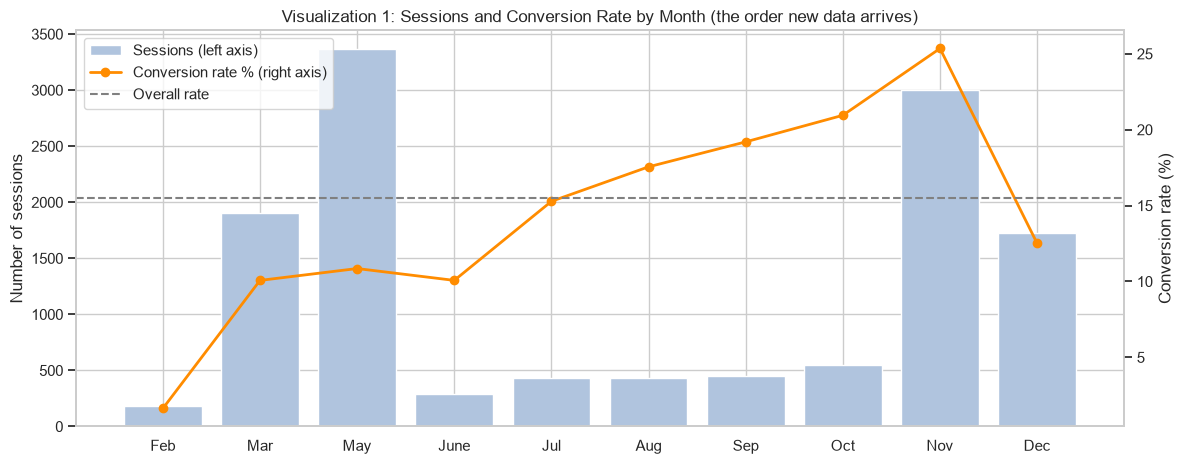

In [3]:
# --- Visualization 1: how much data arrives each month, and its conversion rate ---
fig, ax1 = plt.subplots(figsize=(12, 4.8))
ax1.bar(monthly.index.astype(str), monthly["sessions"], color="lightsteelblue", label="Sessions (left axis)")
ax1.set_ylabel("Number of sessions")
ax2 = ax1.twinx()                                   # second y-axis for the rate
ax2.plot(monthly.index.astype(str), monthly["conversion rate"] * 100, "o-", color="darkorange", lw=2,
         label="Conversion rate % (right axis)")
ax2.axhline(K_TOTAL / N_TOTAL * 100, color="gray", linestyle="--", label="Overall rate")
ax2.set_ylabel("Conversion rate (%)")
ax2.grid(False)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper left")
ax1.set_title("Visualization 1: Sessions and Conversion Rate by Month (the order new data arrives)")
plt.tight_layout()
plt.show()

The data is clean: no missing values, and every column has the expected values. There are 125 fully duplicated rows, but they are mostly very short sessions with all-zero activity counts, which different users can produce, so they were kept.

**Key facts for the Bayesian model:**
- Overall, **1,908 of 12,330 sessions (15.47%) ended in a purchase.** This is the conversion rate *θ* the model estimates.
- The data arrives in **ten monthly batches** of very different sizes, from 184 sessions in February to 3,364 in May.
- The monthly conversion rate is **not stable**. It rises from **1.6% in February** to **25.4% in November** (holiday shopping), then falls to 12.5% in December. This matters later: a simple model that pools all months assumes one constant rate.

## 4. Analytical Model Description

**Bayes' rule.** For an unknown parameter *θ* and observed data *D*:

$$\underbrace{p(\theta \mid D)}_{\text{posterior}} = \frac{\overbrace{p(D \mid \theta)}^{\text{likelihood}} \; \overbrace{p(\theta)}^{\text{prior}}}{p(D)} \;\;\propto\;\; \text{likelihood} \times \text{prior}$$

- **Prior** $p(\theta)$: what we believe about the conversion rate *before* seeing the data.
- **Likelihood** $p(D \mid \theta)$: how probable the observed purchases are for each possible *θ*.
- **Posterior** $p(\theta \mid D)$: our updated belief *after* seeing the data.

**Likelihood: Bernoulli / Binomial.** Each session is a yes/no outcome, so it is modeled as a **Bernoulli** trial with purchase probability *θ*. For *k* purchases in *n* independent sessions, the likelihood is **Binomial**: $p(D \mid \theta) \propto \theta^k (1-\theta)^{n-k}$. This is the natural model for any count of successes in a fixed number of independent tries.

**Prior: Beta(2, 18).** The **Beta** distribution is the standard prior for a probability because it only takes values between 0 and 1. I chose **Beta(2, 18)** because:
- **Its mean is 2 / (2 + 18) = 10%.** Before seeing this store's data, a reasonable expectation is that only a small share of sessions end in a purchase.
- **It is weak.** Its 95% range is about 1% to 28%, so it allows a wide range of rates. It is worth only 2 + 18 = **20 sessions of evidence**, so the data quickly takes over.
- **It is conjugate** to the Binomial likelihood: a Beta prior times a Binomial likelihood gives a **Beta posterior**, which can be calculated exactly and used to check the PyMC results.

**Posterior (exact formula).** With prior Beta(α, β) and *k* purchases in *n* sessions:

$$\theta \mid D \;\sim\; \text{Beta}(\alpha + k,\; \beta + n - k)$$

The posterior mean is $\frac{\alpha + k}{\alpha + \beta + n}$, a **weighted average** of the prior mean and the observed rate *k/n*. With little data, it stays close to the prior. With a lot of data, it moves to the observed rate.

**Sequential updating.** Because the posterior is again a Beta distribution, it becomes the prior for the next batch of data: add that batch's purchases to α and its non-purchases to β. The order of the batches does not change the final answer, but it shows how beliefs evolve.

**Credible interval.** A **95% credible interval** is the range that contains the true *θ* with 95% posterior probability. Unlike a frequentist confidence interval, it can be read directly as "there is a 95% probability that θ is in this range, given the data and the prior."

**Posterior predictive.** To **predict** the number of purchases in the next *m* sessions, average the Binomial over the posterior, which gives a **Beta-Binomial** distribution. It includes both the randomness of sessions *and* our uncertainty about *θ*.

**Frequentist comparison: maximum likelihood (MLE).** The MLE is the value of *θ* that makes the data most likely: $\hat\theta_{MLE} = k/n$. It uses no prior, treats *θ* as a fixed unknown number, and measures uncertainty with a 95% **confidence interval** (Wald: $\hat\theta \pm 1.96\sqrt{\hat\theta(1-\hat\theta)/n}$).

## 5. The Architectural Model (Pipeline) Used

```
 online_shoppers_intention.csv
        │
        ▼
 [1] Load & validate ──────── file, required columns, allowed values        (Sections 2–3)
        │
        ▼
 [2] Preprocess ───────────── Revenue → purchase (1/0), months in order    (Section 3)
        │
        ▼
 [3] Model functions ──────── Beta–Binomial update · summaries · MLE · PyMC model   (Section 6)
        │
        ▼
 [4] Check assumptions ────── constant θ across months? prior sensitivity  (Section 7)
        │
        ▼
 [5] Prior ──► + data ──► Posterior
        │        • exact conjugate posterior + PyMC MCMC posterior          (Section 9)
        │        • month-by-month updating (posterior → next prior)
        │        • simulated stream of new sessions from 3 different priors
        ▼
 [6] Results & validation ─── posterior plots · PyMC vs exact · one-month-ahead predictions  (Sections 10–11)
        │
        ▼
 [7] Bayesian vs. MLE ─────── small samples, coverage, new vs. returning visitors  (Section 12)
        │
        ▼
 [8] Error estimation → improvement (forgetting factor, logistic regression) → conclusion  (Sections 13–15)
```

All random steps use **fixed seeds**, so the notebook gives the same results every time it runs.

## 6. Model Implementation

The model is implemented as small, reusable functions. Each function checks its inputs and raises a clear error for impossible values (for example, more purchases than sessions).

In [4]:
# --- Prior chosen in Section 4: Beta(2, 18), mean 10%, worth about 20 sessions of evidence ---
PRIOR_A, PRIOR_B = 2.0, 18.0

def beta_update(a, b, purchases, sessions):
    """Conjugate update: Beta(a, b) prior + k purchases in n sessions -> Beta(a + k, b + n - k) posterior."""
    if a <= 0 or b <= 0:
        raise ValueError("Beta parameters a and b must be positive.")
    if sessions < 0 or not 0 <= purchases <= sessions:
        raise ValueError("Need sessions >= 0 and 0 <= purchases <= sessions.")
    return a + purchases, b + sessions - purchases

def beta_summary(a, b, cred=0.95):
    """Posterior mean, standard deviation, and equal-tailed credible interval of a Beta(a, b)."""
    lo, hi = stats.beta.ppf([(1 - cred) / 2, (1 + cred) / 2], a, b)
    return {"mean": a / (a + b), "sd": stats.beta.std(a, b), "CrI lower": lo, "CrI upper": hi, "CrI width": hi - lo}

def mle_summary(purchases, sessions, conf=0.95):
    """Frequentist MLE (k/n) with a Wald confidence interval."""
    if sessions <= 0 or not 0 <= purchases <= sessions:
        raise ValueError("Need sessions > 0 and 0 <= purchases <= sessions.")
    p = purchases / sessions
    half = stats.norm.ppf((1 + conf) / 2) * np.sqrt(p * (1 - p) / sessions)
    return {"MLE": p, "CI lower": p - half, "CI upper": p + half, "CI width": 2 * half}

def build_pymc_model(purchases_array, a=PRIOR_A, b=PRIOR_B):
    """PyMC version of the same model: Beta prior on theta, Bernoulli likelihood for each session."""
    y = np.asarray(purchases_array)
    if y.size == 0 or not np.isin(y, [0, 1]).all():
        raise ValueError("purchases_array must be a non-empty array of 0s and 1s.")
    with pm.Model() as model:
        theta = pm.Beta("theta", alpha=a, beta=b)          # prior
        pm.Bernoulli("obs", p=theta, observed=y)            # likelihood (one yes/no per session)
    return model

# Quick self-tests with tiny, hand-checkable numbers
assert beta_update(2, 18, 3, 10) == (5, 25)                 # 2 + 3 = 5, 18 + 7 = 25
assert abs(beta_summary(1, 1)["mean"] - 0.5) < 1e-12        # a flat prior has mean 0.5
assert abs(mle_summary(5, 10)["MLE"] - 0.5) < 1e-12
print("Model functions defined and self-tests passed.")
print("Prior Beta(2, 18):", {k: round(v, 4) for k, v in beta_summary(PRIOR_A, PRIOR_B).items()})

Model functions defined and self-tests passed.
Prior Beta(2, 18): {'mean': 0.1, 'sd': np.float64(0.0655), 'CrI lower': np.float64(0.013), 'CrI upper': np.float64(0.2603), 'CrI width': np.float64(0.2473)}


## 7. Assumptions Verification

| Assumption | Why it matters | How it is checked |
|---|---|---|
| **Independent sessions** | The Binomial likelihood assumes one session does not affect another. | By design: the UCI data has one session per user over a year. |
| **Constant conversion rate *θ*** | Pooling all months into one posterior assumes the same *θ* every month. | Chi-square test of whether the conversion rate differs by month. |
| **Prior does not dominate** | The conclusions should come from the data, not from the analyst's prior choice. | Prior sensitivity: compare posteriors from three very different priors. |
| **MCMC converged** (PyMC) | Sampling results are only valid if the chains converged. | r-hat and effective sample size, checked in Section 11. |

In [5]:
# --- Check 1: is the conversion rate the same every month? (chi-square test of homogeneity) ---
table = pd.crosstab(shop["Month"], shop["purchase"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"Chi-square = {chi2:.1f}, degrees of freedom = {dof}, p-value = {p_value:.2e}")
print("Monthly conversion rates range from "
      f"{monthly['conversion rate'].min():.1%} ({monthly['conversion rate'].idxmin()}) to "
      f"{monthly['conversion rate'].max():.1%} ({monthly['conversion rate'].idxmax()})\n")

# --- Check 2: prior sensitivity on the full dataset ---
# A flat prior (no opinion), my weak prior, and a strong prior that is deliberately wrong (mean 40%, worth 100 sessions)
PRIORS = {"Flat Beta(1, 1)": (1, 1), "Weak Beta(2, 18) [chosen]": (PRIOR_A, PRIOR_B), "Strong & wrong Beta(40, 60)": (40, 60)}
sensitivity = pd.DataFrame({name: beta_summary(*beta_update(a, b, K_TOTAL, N_TOTAL)) for name, (a, b) in PRIORS.items()}).T
sensitivity.insert(0, "prior mean", [a / (a + b) for a, b in PRIORS.values()])
sensitivity

Chi-square = 384.9, degrees of freedom = 9, p-value = 2.24e-77
Monthly conversion rates range from 1.6% (Feb) to 25.4% (Nov)



,prior mean,mean,sd,CrI lower,CrI upper,CrI width
"Flat Beta(1, 1)",0.5000,0.1548,0.0033,0.1485,0.1612,0.0128
"Weak Beta(2, 18) [chosen]",0.1000,0.1547,0.0033,0.1483,0.1611,0.0128
"Strong & wrong Beta(40, 60)",0.4000,0.1567,0.0033,0.1504,0.1632,0.0128


**Results of the checks.**
- **Independence:** satisfied by the way the dataset was built (one session per user).
- **Constant rate:** **not satisfied.** The chi-square test gives *p* ≈ 2 × 10⁻⁷⁷, so the conversion rate clearly differs by month. The pooled posterior is still a valid summary of the **average** rate over the year, but it will be poor at predicting any single month. Section 11.2 measures this, and Section 14.1 improves on it.
- **Prior sensitivity:** satisfied. With all 12,330 sessions, a flat prior, my weak prior, and a strong prior that is deliberately wrong (centered on 40%) all give posterior means between **15.47% and 15.67%**, with the same interval width. The data overwhelms the prior, so the conclusions do not depend on my choice.
- **MCMC convergence:** checked in Section 11.1.

## 8. Deployment

In production, a Bayesian conversion model is very easy to deploy because its whole "memory" is just **two numbers**, the posterior parameters (α, β). An adaptive system would:
1. **Store** the current posterior (α, β).
2. **Update** it when each new batch of sessions arrives: α += purchases, β += non-purchases. This takes microseconds and never needs the old raw data.
3. **Predict** upcoming purchases with the posterior predictive (Beta-Binomial), giving a forecast *with an uncertainty range* that the business can plan around.
4. **Decide**, for example with **Thompson sampling**: draw a plausible *θ* from each page's posterior and show the page with the highest draw. This balances trying new options with using the best-known one, and it is how many recommendation and ad systems learn online.

The code below shows steps 2 and 3: the forecast a deployed model would give for the next 1,000 sessions after learning from all the data.

In [6]:
# --- Posterior after all 12,330 sessions (the "state" a deployed model would store) ---
post_a, post_b = beta_update(PRIOR_A, PRIOR_B, K_TOTAL, N_TOTAL)
print(f"Stored model state: alpha = {post_a:,.0f}, beta = {post_b:,.0f}")

# --- Forecast for the next m sessions: Beta-Binomial posterior predictive ---
def forecast_purchases(a, b, m, cred=0.90):
    """Expected purchases in the next m sessions, with a credible range."""
    if m <= 0:
        raise ValueError("m must be a positive number of sessions.")
    dist = stats.betabinom(m, a, b)
    lo, hi = dist.ppf([(1 - cred) / 2, (1 + cred) / 2])
    return {"next sessions": m, "expected purchases": dist.mean(), "90% range low": int(lo), "90% range high": int(hi)}

pd.DataFrame([forecast_purchases(post_a, post_b, m) for m in (100, 1000, 10000)])

Stored model state: alpha = 1,910, beta = 10,440


,next sessions,expected purchases,90% range low,90% range high
0,100,15.4656,10,22
1,1000,154.6559,135,174
2,10000,"1,546.5587",1467,1627


**Deployment takeaway.** After all the data, the model's entire state is just **α = 1,910 and β = 10,440**. From that, it forecasts about **155 purchases in the next 1,000 sessions** (90% range: 135 to 174). The range is wider than the uncertainty in *θ* alone, because individual sessions are random. Forecasts like this let a store plan inventory and staffing *with* a measure of risk, and the model can be updated in real time without storing old sessions. However, Section 11.2 shows that because the rate changes by season, a deployed model also needs a way to forget old data (Section 14.1).

## 9. Execution

### 9.1 Prior → posterior with all the data (exact conjugate formula)

In [7]:
# --- Exact posterior: Beta(2 + purchases, 18 + non-purchases) ---
prior_stats = beta_summary(PRIOR_A, PRIOR_B)
post_stats = beta_summary(post_a, post_b)
mle_stats = mle_summary(K_TOTAL, N_TOTAL)

print(f"Data: {K_TOTAL:,} purchases in {N_TOTAL:,} sessions")
print(f"Prior:     Beta({PRIOR_A:.0f}, {PRIOR_B:.0f})  mean = {prior_stats['mean']:.4f}, "
      f"95% CrI = ({prior_stats['CrI lower']:.4f}, {prior_stats['CrI upper']:.4f})")
print(f"Posterior: Beta({post_a:,.0f}, {post_b:,.0f})  mean = {post_stats['mean']:.4f}, "
      f"95% CrI = ({post_stats['CrI lower']:.4f}, {post_stats['CrI upper']:.4f})")
print(f"MLE:       k/n = {mle_stats['MLE']:.4f}, 95% CI = ({mle_stats['CI lower']:.4f}, {mle_stats['CI upper']:.4f})")

Data: 1,908 purchases in 12,330 sessions
Prior:     Beta(2, 18)  mean = 0.1000, 95% CrI = (0.0130, 0.2603)
Posterior: Beta(1,910, 10,440)  mean = 0.1547, 95% CrI = (0.1483, 0.1611)
MLE:       k/n = 0.1547, 95% CI = (0.1484, 0.1611)


### 9.2 The same model in PyMC (MCMC sampling)

PyMC does not use the conjugate formula. It builds the model from the prior and likelihood and draws samples from the posterior with the **NUTS** MCMC algorithm. This is the general method that also works for models with no exact formula (like the logistic regression in Section 14). Here, the exact answer from 9.1 lets us check it.

In [8]:
# --- Build and sample the PyMC model: 4 chains x 2,000 draws after 1,000 tuning steps ---
pymc_model = build_pymc_model(shop["purchase"].values)
with pymc_model:
    trace = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42, progressbar=False)

theta_draws = trace.posterior["theta"].values.ravel()     # all 8,000 posterior draws of theta
print(f"PyMC drew {theta_draws.size:,} posterior samples of theta")
print(f"PyMC posterior mean = {theta_draws.mean():.4f}, "
      f"95% CrI = ({np.percentile(theta_draws, 2.5):.4f}, {np.percentile(theta_draws, 97.5):.4f})")

PyMC drew 8,000 posterior samples of theta
PyMC posterior mean = 0.1547, 95% CrI = (0.1485, 0.1613)


### 9.3 Updating month by month as new data arrives

Each month is treated as a new batch of data. The posterior after one month becomes the prior for the next.

In [9]:
# --- Sequential updating: start from the prior, add one month at a time ---
a, b = PRIOR_A, PRIOR_B
seq_rows = [{"after month": "(prior)", "sessions so far": 0, **beta_summary(a, b), "month's own rate": np.nan}]
seq_params = [("prior", a, b)]
seen = 0
for month, row in monthly.iterrows():
    a, b = beta_update(a, b, row["purchases"], row["sessions"])   # today's posterior = tomorrow's prior
    seen += row["sessions"]
    seq_rows.append({"after month": month, "sessions so far": seen, **beta_summary(a, b),
                     "month's own rate": row["conversion rate"]})
    seq_params.append((month, a, b))

sequential = pd.DataFrame(seq_rows).set_index("after month")
sequential

,sessions so far,mean,sd,CrI lower,CrI upper,CrI width,month's own rate
after month,,,,,,,
(prior),0.0000,0.1000,0.0655,0.0130,0.2603,0.2473,NaN
Feb,184.0000,0.0245,0.0108,0.0080,0.0497,0.0416,0.0163
Mar,"2,091.0000",0.0933,0.0063,0.0813,0.1061,0.0248,0.1007
May,"5,455.0000",0.1026,0.0041,0.0947,0.1108,0.0161,0.1085
June,"5,743.0000",0.1026,0.0040,0.0949,0.1105,0.0157,0.1007
Jul,"6,175.0000",0.1061,0.0039,0.0985,0.1138,0.0153,0.1528
Aug,"6,608.0000",0.1106,0.0039,0.1032,0.1183,0.0151,0.1755
Sep,"7,056.0000",0.1157,0.0038,0.1084,0.1233,0.0149,0.1920
Oct,"7,605.0000",0.1225,0.0038,0.1152,0.1299,0.0147,0.2095


### 9.4 Simulation: a stream of new sessions from three different priors

To isolate *how* evidence changes the posterior, I shuffled all sessions into a random order (so the rate is stable) and fed them to the model **50 sessions at a time**, starting from the three priors used in Section 7.

In [10]:
# --- Simulated data stream: random order removes the month-to-month changes ---
rng = np.random.default_rng(42)
stream = rng.permutation(shop["purchase"].values)
checkpoints = np.arange(0, 2001, 50)                     # look at the posterior every 50 sessions, up to 2,000

stream_rows = []
for name, (a0, b0) in PRIORS.items():
    for n_seen in checkpoints:
        k_seen = int(stream[:n_seen].sum())
        stream_rows.append({"prior": name, "sessions seen": n_seen,
                            **beta_summary(*beta_update(a0, b0, k_seen, n_seen))})
stream_df = pd.DataFrame(stream_rows)

# Show a few checkpoints for each prior
stream_df[stream_df["sessions seen"].isin([0, 50, 200, 500, 2000])].pivot(
    index="sessions seen", columns="prior", values="mean")

prior,"Flat Beta(1, 1)","Strong & wrong Beta(40, 60)","Weak Beta(2, 18) [chosen]"
sessions seen,,,
0,0.5000,0.4000,0.1000
50,0.1154,0.3000,0.1000
200,0.1436,0.2267,0.1364
500,0.1653,0.2033,0.1615
2000,0.1553,0.1667,0.1545


## 10. Results

### 10.1 Prior, likelihood, and posterior

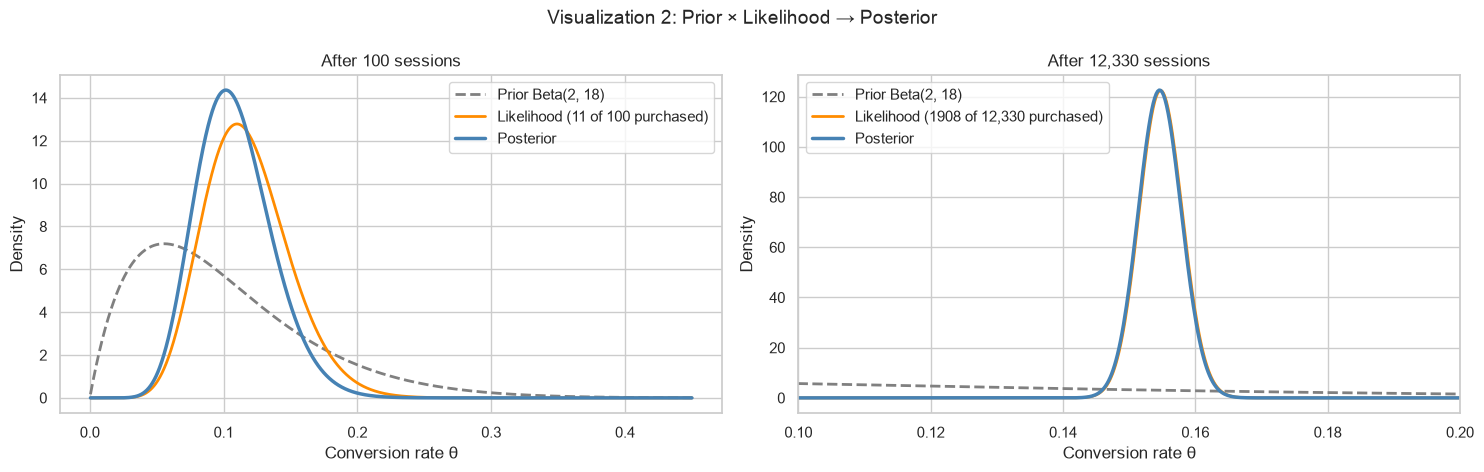

In [11]:
# --- Visualization 2: prior x likelihood -> posterior, after 100 sessions and after all 12,330 ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, n_seen, xmax in [(axes[0], 100, 0.45), (axes[1], N_TOTAL, 0.45)]:
    k_seen = int(stream[:n_seen].sum())
    x = np.linspace(0.0005, xmax, 2000)
    prior_pdf = stats.beta.pdf(x, PRIOR_A, PRIOR_B)
    like = stats.binom.pmf(k_seen, n_seen, x)
    like_pdf = like / np.trapezoid(like, x)              # rescale the likelihood so it can share the axis
    post_pdf = stats.beta.pdf(x, *beta_update(PRIOR_A, PRIOR_B, k_seen, n_seen))
    ax.plot(x, prior_pdf, color="gray", lw=2, linestyle="--", label="Prior Beta(2, 18)")
    ax.plot(x, like_pdf, color="darkorange", lw=2, label=f"Likelihood ({k_seen} of {n_seen:,} purchased)")
    ax.plot(x, post_pdf, color="steelblue", lw=2.5, label="Posterior")
    ax.set_title(f"After {n_seen:,} sessions")
    ax.set_xlabel("Conversion rate θ")
    ax.set_ylabel("Density")
    ax.legend()
axes[1].set_xlim(0.10, 0.20)                              # zoom in: with all the data the curves are very narrow
fig.suptitle("Visualization 2: Prior × Likelihood → Posterior", fontsize=14)
plt.tight_layout()
plt.show()

**How Bayes' rule combines the prior and the data.**
- **After 100 sessions (left):** 11 purchases were observed. The **prior** (gray) is wide and centered on 10%. The **likelihood** (orange) peaks at the observed rate of 11%. The **posterior** (blue) lies between them, slightly pulled toward the prior, and it is **narrower than either**, because it combines two sources of information.
- **After 12,330 sessions (right, zoomed in):** the likelihood is so sharp that the prior looks almost flat. The posterior sits exactly on the likelihood at about **15.5%**. With lots of data, the prior has almost no influence.

### 10.2 How the posterior changes month by month

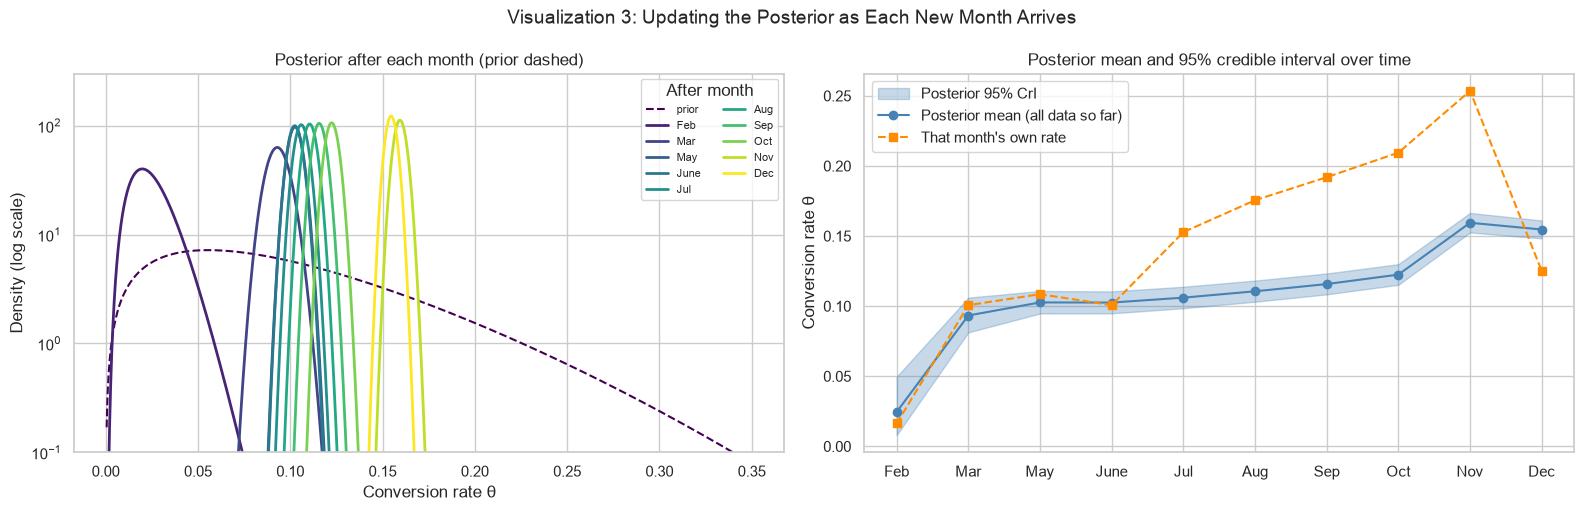

In [12]:
# --- Visualization 3: posterior after each month (left) and its mean and 95% CrI vs. each month's own rate (right) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
x = np.linspace(0.0005, 0.35, 3000)
colors = plt.cm.viridis(np.linspace(0, 1, len(seq_params)))
for (label, a_, b_), c in zip(seq_params, colors):
    axes[0].plot(x, stats.beta.pdf(x, a_, b_), color=c, lw=2 if label != "prior" else 1.5,
                 linestyle="--" if label == "prior" else "-", label=str(label))
axes[0].set_xlabel("Conversion rate θ")
axes[0].set_ylabel("Density (log scale)")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-1, 300)
axes[0].set_title("Posterior after each month (prior dashed)")
axes[0].legend(ncol=2, fontsize=8, title="After month")

seq_plot = sequential.iloc[1:]
xs = np.arange(len(seq_plot))
axes[1].fill_between(xs, seq_plot["CrI lower"], seq_plot["CrI upper"], color="steelblue", alpha=0.3, label="Posterior 95% CrI")
axes[1].plot(xs, seq_plot["mean"], "o-", color="steelblue", label="Posterior mean (all data so far)")
axes[1].plot(xs, seq_plot["month's own rate"], "s--", color="darkorange", label="That month's own rate")
axes[1].set_xticks(xs)
axes[1].set_xticklabels([str(m) for m in seq_plot.index])
axes[1].set_ylabel("Conversion rate θ")
axes[1].set_title("Posterior mean and 95% credible interval over time")
axes[1].legend()
fig.suptitle("Visualization 3: Updating the Posterior as Each New Month Arrives", fontsize=14)
plt.tight_layout()
plt.show()

**How the posterior evolves as each month arrives.**
- **The posterior narrows with every month.** The 95% credible interval shrinks from about **25 percentage points** wide (prior only) to **4.2 points** after February and **1.3 points** after all ten months. More evidence means more certainty.
- **Early data moves the posterior a lot; later data moves it less.** After February (only 3 purchases in 184 sessions), the mean drops from the prior's 10% to **2.5%**. After March adds 1,907 sessions, it jumps back to **9.3%**. Later months move it only slightly, because each new month is a smaller share of all the evidence.
- **The pooled posterior lags behind the real changes.** From July to November, each month's own rate (orange) climbs to 25%, but the posterior mean (blue) only rises slowly to 16%. In December, the actual rate drops to 12.5%, while the posterior stays near 15.5%. Because the model treats all past months as equally relevant, it estimates the **year-long average**, not the current rate. Its narrow interval reflects certainty about that average, not about next month.

### 10.3 How the starting prior stops mattering as evidence grows

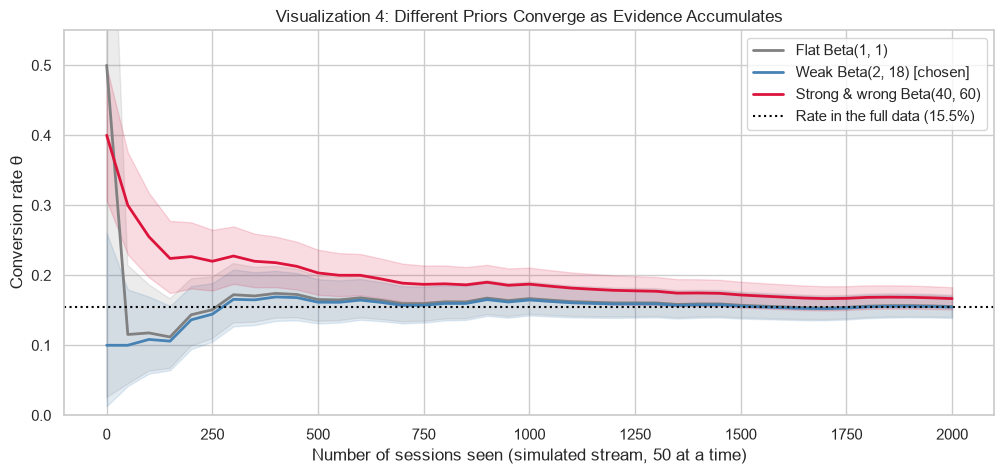

In [13]:
# --- Visualization 4: posterior mean and 95% CrI vs. number of sessions seen, for three priors ---
fig, ax = plt.subplots(figsize=(12, 5))
palette = {"Flat Beta(1, 1)": "gray", "Weak Beta(2, 18) [chosen]": "steelblue", "Strong & wrong Beta(40, 60)": "crimson"}
for name, grp in stream_df.groupby("prior", sort=False):
    ax.plot(grp["sessions seen"], grp["mean"], color=palette[name], lw=2, label=name)
    ax.fill_between(grp["sessions seen"], grp["CrI lower"], grp["CrI upper"], color=palette[name], alpha=0.15)
ax.axhline(K_TOTAL / N_TOTAL, color="black", linestyle=":", label=f"Rate in the full data ({K_TOTAL / N_TOTAL:.1%})")
ax.set_xlabel("Number of sessions seen (simulated stream, 50 at a time)")
ax.set_ylabel("Conversion rate θ")
ax.set_ylim(0, 0.55)
ax.set_title("Visualization 4: Different Priors Converge as Evidence Accumulates")
ax.legend()
plt.show()

**Different priors converge as evidence accumulates.** In the simulated stream, where the rate is stable:
- The **flat prior** (gray) starts at 50% but drops close to the data within the first 50 sessions, because it is worth only 2 sessions of evidence.
- My **weak prior** (blue) starts at 10% and moves to the data almost as fast.
- The **strong, wrong prior** (red) starts at 40% and is worth 100 sessions, so it takes much longer to correct. It is still at 20% after 500 sessions, and only gets close to the truth after about 2,000 sessions.

This shows both the **strength** and the **risk** of Bayesian priors. A sensible, weak prior helps when data is scarce and is quickly overridden. A confident but wrong prior can bias results until enough data arrives.

## 11. Model Validation

### 11.1 Does PyMC agree with the exact posterior? Did the MCMC converge?

In [14]:
# --- Compare PyMC's samples with the exact Beta posterior ---
exact = beta_summary(post_a, post_b)
validation = pd.DataFrame({
    "exact (conjugate)": [exact["mean"], exact["sd"], exact["CrI lower"], exact["CrI upper"]],
    "PyMC (MCMC)": [theta_draws.mean(), theta_draws.std(ddof=1),
                    np.percentile(theta_draws, 2.5), np.percentile(theta_draws, 97.5)],
}, index=["posterior mean", "posterior sd", "95% CrI lower", "95% CrI upper"])
validation["difference"] = validation["PyMC (MCMC)"] - validation["exact (conjugate)"]

# --- Convergence diagnostics: r-hat close to 1.00 and a large effective sample size mean the chains agree ---
diag = az.summary(trace, var_names=["theta"])
print(f"r-hat = {float(diag['r_hat'].iloc[0]):.3f}   effective sample size (bulk) = {float(diag['ess_bulk'].iloc[0]):,.0f}")
validation

r-hat = 1.001   effective sample size (bulk) = 3,838


,exact (conjugate),PyMC (MCMC),difference
posterior mean,0.1547,0.1547,0.0000
posterior sd,0.0033,0.0032,-0.0000
95% CrI lower,0.1483,0.1485,0.0002
95% CrI upper,0.1611,0.1613,0.0002


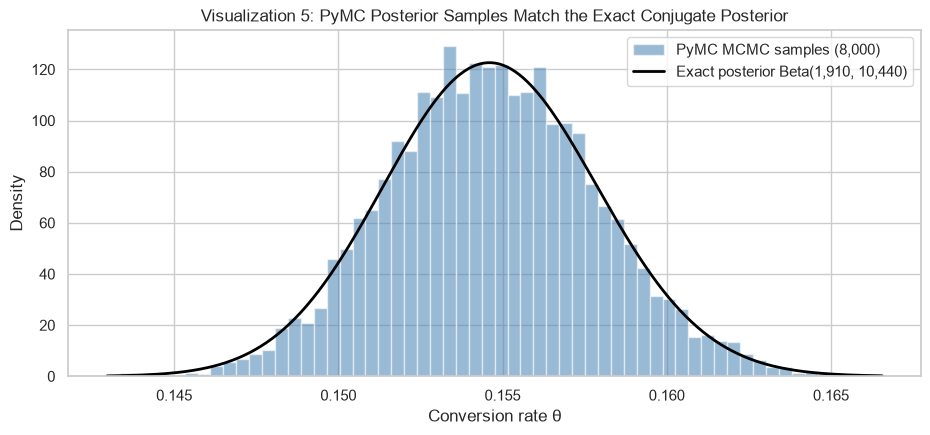

In [15]:
# --- Visualization 5: histogram of PyMC draws with the exact posterior curve on top ---
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(theta_draws, bins=60, density=True, color="steelblue", alpha=0.55, label="PyMC MCMC samples (8,000)")
x = np.linspace(theta_draws.min(), theta_draws.max(), 400)
ax.plot(x, stats.beta.pdf(x, post_a, post_b), color="black", lw=2, label=f"Exact posterior Beta({post_a:,.0f}, {post_b:,.0f})")
ax.set_xlabel("Conversion rate θ")
ax.set_ylabel("Density")
ax.set_title("Visualization 5: PyMC Posterior Samples Match the Exact Conjugate Posterior")
ax.legend()
plt.show()

### 11.2 Can the model predict next month? (one-month-ahead check)

A model is only useful if it predicts **new** data. For each month, I used the posterior from all *earlier* months to predict how many purchases the next month would have (Beta-Binomial, 90% range), and then compared it with what actually happened.

In [16]:
# --- One-month-ahead predictions using only past data ---
def one_step_ahead(decay=1.0):
    """Predict each month from earlier months. decay < 1 down-weights old data (used in Section 14)."""
    a, b = PRIOR_A, PRIOR_B
    rows = []
    for i, (month, row) in enumerate(monthly.iterrows()):
        if i > 0:                                          # need at least one past month to predict
            n_m, k_m = int(row["sessions"]), int(row["purchases"])
            lo, hi = stats.betabinom(n_m, a, b).ppf([0.05, 0.95])
            rows.append({"month": month, "sessions": n_m, "predicted rate": a / (a + b),
                         "actual rate": k_m / n_m, "predicted purchases": n_m * a / (a + b),
                         "90% range low": int(lo), "90% range high": int(hi), "actual purchases": k_m,
                         "inside 90% range?": lo <= k_m <= hi})
        # decay old evidence toward the prior, then add this month's data
        a = PRIOR_A + decay * (a - PRIOR_A)
        b = PRIOR_B + decay * (b - PRIOR_B)
        a, b = beta_update(a, b, row["purchases"], row["sessions"])
    return pd.DataFrame(rows).set_index("month")

ahead = one_step_ahead(decay=1.0)
print(f"Months inside the 90% predictive range: {ahead['inside 90% range?'].sum()} of {len(ahead)}")
print(f"Mean absolute error of predicted rate: {(ahead['predicted rate'] - ahead['actual rate']).abs().mean():.2%} points")
ahead

Months inside the 90% predictive range: 1 of 9
Mean absolute error of predicted rate: 6.15% points


,sessions,predicted rate,actual rate,predicted purchases,90% range low,90% range high,actual purchases,inside 90% range?
month,,,,,,,,
Mar,1907,0.0245,0.1007,46.7402,17,87,192,False
May,3364,0.0933,0.1085,313.9308,270,360,365,False
June,288,0.1026,0.1007,29.5627,21,38,29,True
Jul,432,0.1026,0.1528,44.3019,34,55,66,False
Aug,433,0.1061,0.1755,45.9211,35,57,76,False
Sep,448,0.1106,0.1920,49.5450,39,61,86,False
Oct,549,0.1157,0.2095,63.5431,51,77,115,False
Nov,2998,0.1225,0.2535,367.2304,333,402,760,False
Dec,1727,0.1595,0.1251,275.3966,249,303,216,False


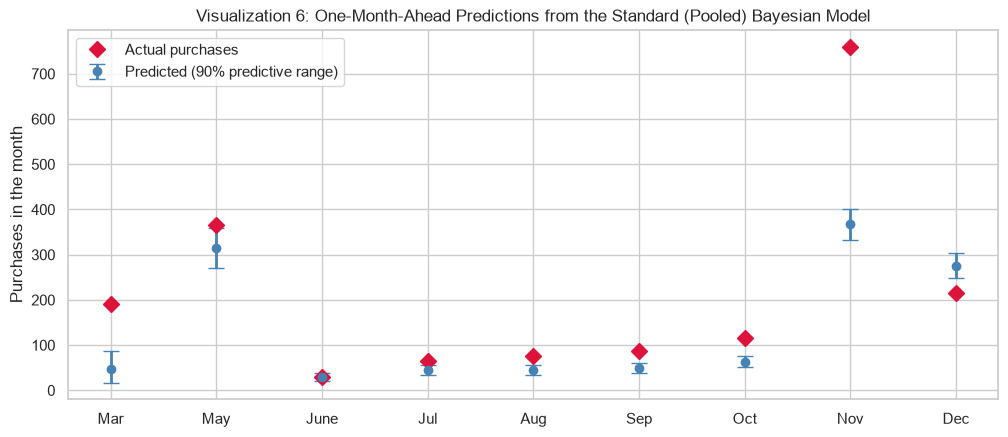

In [17]:
# --- Visualization 6: predicted vs. actual purchases each month, with the 90% predictive range ---
fig, ax = plt.subplots(figsize=(12, 4.8))
xs = np.arange(len(ahead))
ax.errorbar(xs, ahead["predicted purchases"],
            yerr=[ahead["predicted purchases"] - ahead["90% range low"], ahead["90% range high"] - ahead["predicted purchases"]],
            fmt="o", color="steelblue", capsize=6, lw=2, label="Predicted (90% predictive range)")
ax.plot(xs, ahead["actual purchases"], "D", color="crimson", ms=8, label="Actual purchases")
ax.set_xticks(xs)
ax.set_xticklabels([str(m) for m in ahead.index])
ax.set_ylabel("Purchases in the month")
ax.set_title("Visualization 6: One-Month-Ahead Predictions from the Standard (Pooled) Bayesian Model")
ax.legend()
plt.show()

**Validation results.**
- **PyMC is correct.** Its posterior mean, standard deviation, and 95% credible interval match the exact conjugate posterior to within 0.0002, and the histogram of its 8,000 draws follows the exact curve (Visualization 5). The chains converged: **r-hat = 1.001** (the target is below 1.01) and the effective sample size is about **3,800**.
- **The pooled model predicts new months poorly.** Only **1 of 9** months fell inside the 90% predictive range, and the predicted rate was off by **6.2 percentage points** on average. The model's ranges are too narrow because it assumes one constant rate, while the real rate changes with the season. November is the worst: the model predicted about 367 purchases and there were **760**. This failure is the practical cost of the broken "constant rate" assumption found in Section 7.

## 12. Analysis

### 12.1 Bayesian vs. frequentist (MLE) with small samples

With 12,330 sessions, the Bayesian posterior mean and the MLE are almost identical. The difference appears when data is **scarce**, which is exactly when a new product, page, or user segment has just launched. The table below uses the first few sessions of the random stream.

In [18]:
# --- Bayesian (weak prior) vs. MLE on the first n sessions of the random stream ---
rows = []
for n_seen in [10, 20, 50, 100, 500, 2000]:
    k_seen = int(stream[:n_seen].sum())
    bay = beta_summary(*beta_update(PRIOR_A, PRIOR_B, k_seen, n_seen))
    mle = mle_summary(k_seen, n_seen)
    rows.append({"sessions": n_seen, "purchases": k_seen,
                 "MLE": mle["MLE"], "MLE 95% CI": f"{mle['CI lower']:.3f} to {mle['CI upper']:.3f}",
                 "Bayes mean": bay["mean"], "Bayes 95% CrI": f"{bay['CrI lower']:.3f} to {bay['CrI upper']:.3f}"})
pd.DataFrame(rows).set_index("sessions")

,purchases,MLE,MLE 95% CI,Bayes mean,Bayes 95% CrI
sessions,,,,,
10,1,0.1000,-0.086 to 0.286,0.1000,0.022 to 0.228
20,1,0.0500,-0.046 to 0.146,0.0750,0.016 to 0.173
50,5,0.1000,0.017 to 0.183,0.1000,0.042 to 0.180
100,11,0.1100,0.049 to 0.171,0.1083,0.059 to 0.170
500,82,0.1640,0.132 to 0.196,0.1615,0.131 to 0.194
2000,310,0.1550,0.139 to 0.171,0.1545,0.139 to 0.171


To compare the two approaches fairly, I repeated this **2,000 times**: draw a random sample of *n* sessions, then calculate both estimates. The true rate is the full-data rate (15.47%). I measured:
- **Error (RMSE):** the typical distance between the estimate and the true rate. Smaller is better.
- **Coverage:** how often the 95% interval contains the true rate. It should be close to 95%.

In [19]:
# --- Repeated-sampling comparison of Bayes vs. MLE ---
true_theta = K_TOTAL / N_TOTAL
sim_rng = np.random.default_rng(7)
all_purchases = shop["purchase"].values
z = stats.norm.ppf(0.975)
comp_rows = []
for n_s in [10, 30, 100, 500]:
    k = all_purchases[sim_rng.integers(0, N_TOTAL, size=(2000, n_s))].sum(axis=1)   # 2,000 samples at once
    mle = k / n_s
    wald_half = z * np.sqrt(mle * (1 - mle) / n_s)
    a_post, b_post = PRIOR_A + k, PRIOR_B + n_s - k
    bayes_mean = a_post / (a_post + b_post)
    cri_lo, cri_hi = stats.beta.ppf(0.025, a_post, b_post), stats.beta.ppf(0.975, a_post, b_post)
    comp_rows.append({
        "n": n_s,
        "RMSE: MLE": np.sqrt(np.mean((mle - true_theta) ** 2)),
        "RMSE: Bayes mean": np.sqrt(np.mean((bayes_mean - true_theta) ** 2)),
        "coverage: MLE Wald CI": np.mean((mle - wald_half <= true_theta) & (true_theta <= mle + wald_half)),
        "coverage: Bayes 95% CrI": np.mean((cri_lo <= true_theta) & (true_theta <= cri_hi)),
        "samples with 0 purchases": np.mean(k == 0),
    })
comparison = pd.DataFrame(comp_rows).set_index("n")
comparison

,RMSE: MLE,RMSE: Bayes mean,coverage: MLE Wald CI,coverage: Bayes 95% CrI,samples with 0 purchases
n,,,,,
10,0.1175,0.0530,0.7975,1.0000,0.1890
30,0.0657,0.0446,0.9475,0.9600,0.0060
100,0.0362,0.0315,0.9385,0.9475,0.0000
500,0.0159,0.0155,0.9510,0.9455,0.0000


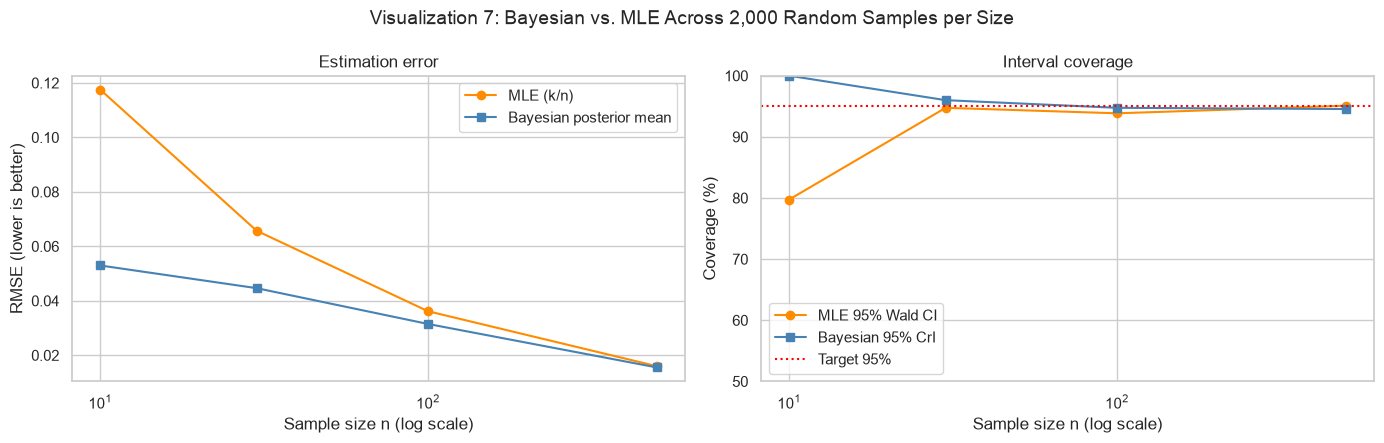

In [20]:
# --- Visualization 7: error and coverage of Bayes vs. MLE as the sample grows ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ns = comparison.index.values
axes[0].plot(ns, comparison["RMSE: MLE"], "o-", color="darkorange", label="MLE (k/n)")
axes[0].plot(ns, comparison["RMSE: Bayes mean"], "s-", color="steelblue", label="Bayesian posterior mean")
axes[0].set_xscale("log")
axes[0].set_xlabel("Sample size n (log scale)")
axes[0].set_ylabel("RMSE (lower is better)")
axes[0].set_title("Estimation error")
axes[0].legend()
axes[1].plot(ns, comparison["coverage: MLE Wald CI"] * 100, "o-", color="darkorange", label="MLE 95% Wald CI")
axes[1].plot(ns, comparison["coverage: Bayes 95% CrI"] * 100, "s-", color="steelblue", label="Bayesian 95% CrI")
axes[1].axhline(95, color="red", linestyle=":", label="Target 95%")
axes[1].set_xscale("log")
axes[1].set_ylim(50, 100)
axes[1].set_xlabel("Sample size n (log scale)")
axes[1].set_ylabel("Coverage (%)")
axes[1].set_title("Interval coverage")
axes[1].legend()
fig.suptitle("Visualization 7: Bayesian vs. MLE Across 2,000 Random Samples per Size", fontsize=14)
plt.tight_layout()
plt.show()

**Bayesian vs. MLE.**
- **With small samples, Bayes is clearly better.** At n = 10, the Bayesian posterior mean's typical error (RMSE 0.053) is **less than half** the MLE's (0.118). About **19% of the samples had zero purchases**, so the MLE claimed a 0% conversion rate with a zero-width confidence interval. The Bayesian estimate never says 0%, because the prior keeps it realistic.
- **The Wald confidence interval fails for small samples.** Its coverage is only about **80%** at n = 10, and the table above shows it can even include negative rates (−8.6% at n = 10). The Bayesian credible interval always stays between 0 and 1. At n = 10 it is conservative (100% coverage), and from n = 30 upward it is close to 95%.
- **With lots of data, the two agree.** By n = 500, the errors and coverages are nearly the same, and with all 12,330 sessions the posterior mean and the MLE are both 15.47% (Section 9.1). When there is plenty of data, the choice of method matters little.

**Strengths of the Bayesian approach here:** it gives sensible answers with little data, its intervals have a direct probability meaning, it produces predictive distributions for future data, and it updates naturally as data arrives. **Weaknesses:** the results depend on the prior when data is scarce (Visualization 4 shows a wrong prior can mislead), and complex models need MCMC, which is slower and requires convergence checks. **Strengths of MLE:** it is simple, fast, needs no prior, and is equally good with large samples.

### 12.2 An AI decision: do new visitors convert better than returning visitors?

A frequentist test answers "is the difference statistically significant?". A Bayesian model answers the question a business actually asks: **"what is the probability that new visitors convert better?"** I gave each group the same Beta(2, 18) prior, updated it with that group's data, and compared 100,000 draws from the two posteriors.

New visitors:       422 purchases / 1,694 sessions
Returning visitors: 1,470 purchases / 10,551 sessions
P(new visitors convert better) = 1.0000
Difference (new − returning): mean = 0.108, 95% CrI = (0.087, 0.130)


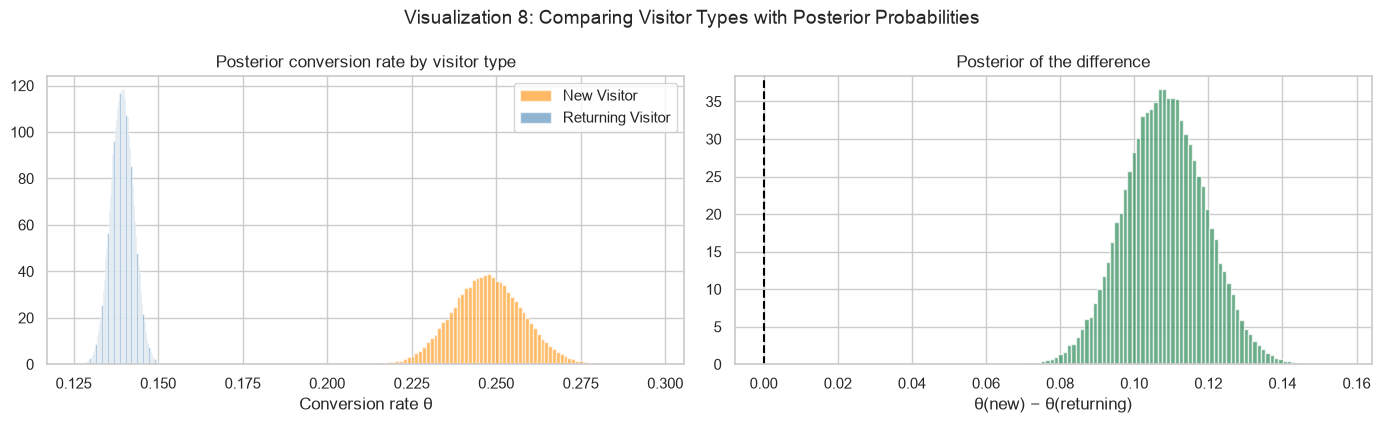

In [21]:
# --- Posterior for each visitor type, then the probability that one rate is higher ---
groups = shop[shop["VisitorType"].isin(["New_Visitor", "Returning_Visitor"])].groupby("VisitorType")["purchase"].agg(["sum", "size"])
draw_rng = np.random.default_rng(11)
post_draws = {}
for vt, row in groups.iterrows():
    a_g, b_g = beta_update(PRIOR_A, PRIOR_B, row["sum"], row["size"])
    post_draws[vt] = draw_rng.beta(a_g, b_g, size=100_000)

diff = post_draws["New_Visitor"] - post_draws["Returning_Visitor"]
print(f"New visitors:       {groups.loc['New_Visitor', 'sum']} purchases / {groups.loc['New_Visitor', 'size']:,} sessions")
print(f"Returning visitors: {groups.loc['Returning_Visitor', 'sum']:,} purchases / {groups.loc['Returning_Visitor', 'size']:,} sessions")
print(f"P(new visitors convert better) = {np.mean(diff > 0):.4f}")
print(f"Difference (new − returning): mean = {diff.mean():.3f}, 95% CrI = ({np.percentile(diff, 2.5):.3f}, {np.percentile(diff, 97.5):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for vt, color in [("New_Visitor", "darkorange"), ("Returning_Visitor", "steelblue")]:
    axes[0].hist(post_draws[vt], bins=80, density=True, alpha=0.6, color=color, label=vt.replace("_", " "))
axes[0].set_xlabel("Conversion rate θ")
axes[0].set_title("Posterior conversion rate by visitor type")
axes[0].legend()
axes[1].hist(diff, bins=80, density=True, color="seagreen", alpha=0.7)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("θ(new) − θ(returning)")
axes[1].set_title("Posterior of the difference")
fig.suptitle("Visualization 8: Comparing Visitor Types with Posterior Probabilities", fontsize=14)
plt.tight_layout()
plt.show()

**Result.** New visitors converted at about **24.9%** and returning visitors at about **13.9%**. The posterior probability that new visitors convert better is essentially **100%** (all 100,000 draws), and the difference is about **10.8 percentage points** (95% CrI: 8.7 to 13.0). For an AI system, this is a direct, decision-ready statement: personalization or offers aimed at first-time visitors are likely to pay off.

### 12.3 Bayesian methods in adaptive learning

An **adaptive learning algorithm** keeps updating its predictions as new data streams in. The Bayesian approach fits this naturally:
- **Updating is built in.** The posterior after today's data is the prior for tomorrow (Section 9.3). There is no need to refit from scratch or store old data.
- **It handles the cold start.** A new product, page, or user segment has very little data. A sensible prior gives reasonable estimates from the first few sessions, where the MLE can say 0% (Section 12.1).
- **It quantifies uncertainty for decisions.** **Thompson sampling** uses posterior draws to decide which option to show next, exploring uncertain options and exploiting good ones automatically. This is widely used in recommendation and online advertising (Russo et al., 2018).
- **It can forget.** As Section 14.1 shows, discounting old evidence lets a Bayesian model adapt when user behavior changes.

**The main lesson from this project:** sequential Bayesian updating is only as good as its assumptions. When the conversion rate changes over time, the model must be told to adapt, or its growing certainty will be about the past rather than the present.

## 13. Error Estimation

In a Bayesian model, uncertainty is described by the **posterior** itself. The posterior standard deviation and the width of the credible interval measure how uncertain *θ* still is. Prediction error is measured on **new** data (Section 11.2).

In [22]:
# --- How uncertainty about theta shrinks as data accumulates (from the month-by-month run) ---
err = sequential[["sessions so far", "mean", "sd", "CrI width"]].copy()
err["sd if θ were known exactly × 1/√n"] = np.sqrt(true_theta * (1 - true_theta) / err["sessions so far"].replace(0, np.nan))

# --- Prediction error on new months (from the one-month-ahead check) ---
pred_err = (ahead["predicted rate"] - ahead["actual rate"])
print(f"Final posterior: sd = {post_stats['sd']:.4f}, 95% CrI width = {post_stats['CrI width']:.4f} "
      f"(± {post_stats['CrI width'] / 2:.2%} points)")
print(f"One-month-ahead prediction error: mean absolute = {pred_err.abs().mean():.2%} points, "
      f"largest = {pred_err.abs().max():.2%} points ({pred_err.abs().idxmax()})")
err

Final posterior: sd = 0.0033, 95% CrI width = 0.0128 (± 0.64% points)
One-month-ahead prediction error: mean absolute = 6.15% points, largest = 13.10% points (Nov)


,sessions so far,mean,sd,CrI width,sd if θ were known exactly × 1/√n
after month,,,,,
(prior),0.0000,0.1000,0.0655,0.2473,NaN
Feb,184.0000,0.0245,0.0108,0.0416,0.0267
Mar,"2,091.0000",0.0933,0.0063,0.0248,0.0079
May,"5,455.0000",0.1026,0.0041,0.0161,0.0049
June,"5,743.0000",0.1026,0.0040,0.0157,0.0048
Jul,"6,175.0000",0.1061,0.0039,0.0153,0.0046
Aug,"6,608.0000",0.1106,0.0039,0.0151,0.0044
Sep,"7,056.0000",0.1157,0.0038,0.0149,0.0043
Oct,"7,605.0000",0.1225,0.0038,0.0147,0.0041


**Sources and size of error.**
- **Uncertainty about the average rate is now small.** The final posterior standard deviation is 0.0033, and the 95% credible interval is about **±0.64 percentage points**. The posterior standard deviation shrinks roughly like 1/√n, matching the last column of the table.
- **Prediction error for a new month is much larger:** about **6.2 percentage points** on average, and **13.1 points** in November. Almost all of this error comes from the **changing conversion rate**, not from too little data.
- **Other sources of error:**
  - **Model error:** a single *θ* for every session ignores visitor type, page behavior, and season. Section 14.2 adds a predictor.
  - **Prior error:** negligible here with 12,330 sessions (Section 7), but important with small samples (Visualization 4).
  - **Sampling (Monte Carlo) error in PyMC:** the MCMC standard error of the posterior mean is tiny (about 0.00005), as shown by the agreement with the exact posterior.
  - **Data coverage:** the data comes from one store over one year, with no January or April sessions, so it may not represent other stores or years.

## 14. Model Improvement

### 14.1 Handling a changing conversion rate: a forgetting factor

The standard model treats a session from February as just as relevant as one from last week. A simple fix used in adaptive systems is a **forgetting factor** (also called discounting or a power prior): before adding each new month, shrink the old evidence toward the prior by a factor *λ* between 0 and 1:

$$\alpha \leftarrow \alpha_0 + \lambda(\alpha - \alpha_0), \qquad \beta \leftarrow \beta_0 + \lambda(\beta - \beta_0)$$

With *λ* = 1 nothing is forgotten (the standard model). With a smaller *λ*, the model mostly trusts recent months and can follow changes faster. I tested several values with the same one-month-ahead check.

In [23]:
# --- Try several forgetting factors with the one-month-ahead check from Section 11 ---
decay_rows = []
for lam in [1.0, 0.7, 0.5, 0.3, 0.1]:
    res = one_step_ahead(decay=lam)
    decay_rows.append({"forgetting factor λ": lam,
                       "mean abs. error (rate)": (res["predicted rate"] - res["actual rate"]).abs().mean(),
                       "months inside 90% range": f"{res['inside 90% range?'].sum()} of {len(res)}"})
decay_table = pd.DataFrame(decay_rows).set_index("forgetting factor λ")
best_lam = decay_table["mean abs. error (rate)"].idxmin()
print(f"Best forgetting factor: λ = {best_lam}")
decay_table

Best forgetting factor: λ = 0.1


,mean abs. error (rate),months inside 90% range
forgetting factor λ,,
1.0000,0.0615,1 of 9
0.7000,0.0604,2 of 9
0.5000,0.0546,2 of 9
0.3000,0.0479,4 of 9
0.1000,0.0435,5 of 9


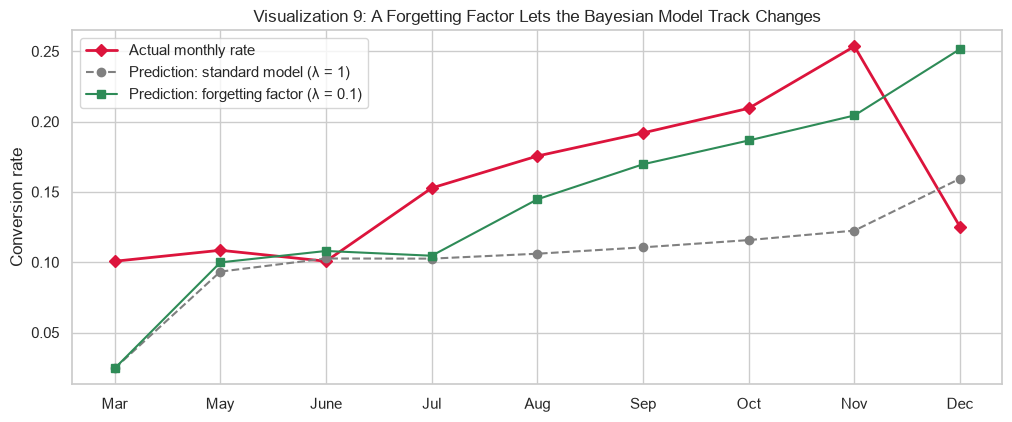

In [24]:
# --- Visualization 9: predicted monthly rate with no forgetting vs. the best forgetting factor ---
standard, adaptive = one_step_ahead(1.0), one_step_ahead(best_lam)
fig, ax = plt.subplots(figsize=(12, 4.6))
xs = np.arange(len(standard))
ax.plot(xs, standard["actual rate"], "D-", color="crimson", lw=2, label="Actual monthly rate")
ax.plot(xs, standard["predicted rate"], "o--", color="gray", label="Prediction: standard model (λ = 1)")
ax.plot(xs, adaptive["predicted rate"], "s-", color="seagreen", label=f"Prediction: forgetting factor (λ = {best_lam})")
ax.set_xticks(xs)
ax.set_xticklabels([str(m) for m in standard.index])
ax.set_ylabel("Conversion rate")
ax.set_title("Visualization 9: A Forgetting Factor Lets the Bayesian Model Track Changes")
ax.legend()
plt.show()

**Improvement results.** Forgetting old data helps. As *λ* decreases, the one-month-ahead error falls from **6.2 points (λ = 1, standard model)** to **4.4 points (λ = 0.1)**, and the number of months inside the 90% predictive range rises from **1 to 5 of 9**. The adaptive model follows the rise from July to November and recovers more quickly in December. The best value tested is the smallest one, which means recent months matter most for this store.

It does not fix everything. The November holiday spike is still underpredicted, because no model based only on past months can know a seasonal spike is coming. The next step would be to add a **seasonal or calendar feature** (such as the dataset's `SpecialDay` variable) or a **hierarchical model** with a separate rate for each month that shares information across months.

### 14.2 Adding a predictor: Bayesian vs. MLE logistic regression

The model so far gives one conversion rate for everyone. A real purchase-prediction model uses **session behavior**. `PageValues` (the average value of the pages a user viewed before buying) was one of the most informative features in the original study of this dataset (Sakar et al., 2019). I fitted the same **logistic regression** two ways:
- **Frequentist:** maximum likelihood with `statsmodels`.
- **Bayesian:** PyMC with weakly informative Normal(0, 2.5) priors on the coefficients.

$$\text{logit}\,P(\text{purchase}) = \beta_0 + \beta_1 \cdot \log(1 + \text{PageValues})$$

The log transform reduces the strong right skew of `PageValues`.

In [25]:
# --- Predictor: log(1 + PageValues), which reduces its heavy right skew ---
x_pv = np.log1p(shop["PageValues"].values)
y = shop["purchase"].values

# --- Frequentist: logistic regression by maximum likelihood ---
mle_fit = sm.Logit(y, sm.add_constant(x_pv)).fit(disp=False)
mle_ci = mle_fit.conf_int()

# --- Bayesian: the same model in PyMC, with weakly informative priors on the coefficients ---
with pm.Model() as logit_model:
    b0 = pm.Normal("intercept", mu=0, sigma=2.5)
    b1 = pm.Normal("slope", mu=0, sigma=2.5)
    pm.Bernoulli("obs", logit_p=b0 + b1 * x_pv, observed=y)
    logit_trace = pm.sample(draws=1000, tune=1000, chains=4, random_seed=42, progressbar=False)

coef = pd.DataFrame({
    "MLE estimate": mle_fit.params,
    "MLE 95% CI": [f"{lo:.3f} to {hi:.3f}" for lo, hi in mle_ci],
    "Bayes posterior mean": [logit_trace.posterior[v].values.mean() for v in ("intercept", "slope")],
    "Bayes 95% CrI": [f"{np.percentile(logit_trace.posterior[v].values, 2.5):.3f} to "
                      f"{np.percentile(logit_trace.posterior[v].values, 97.5):.3f}" for v in ("intercept", "slope")],
}, index=["intercept", "slope (log PageValues)"])

# Predicted purchase probability for a session with no page value vs. one with PageValues = 20
for pv in (0, 20):
    eta = logit_trace.posterior["intercept"].values + logit_trace.posterior["slope"].values * np.log1p(pv)
    p_draws = 1 / (1 + np.exp(-eta))
    print(f"PageValues = {pv:>2}: Bayesian predicted purchase probability = {p_draws.mean():.3f} "
          f"(95% CrI {np.percentile(p_draws, 2.5):.3f} to {np.percentile(p_draws, 97.5):.3f})")
coef

PageValues =  0: Bayesian predicted purchase probability = 0.047 (95% CrI 0.043 to 0.051)
PageValues = 20: Bayesian predicted purchase probability = 0.605 (95% CrI 0.584 to 0.626)


,MLE estimate,MLE 95% CI,Bayes posterior mean,Bayes 95% CrI
intercept,-3.0212,-3.112 to -2.931,-3.0195,-3.107 to -2.932
slope (log PageValues),1.1318,1.090 to 1.174,1.1315,1.090 to 1.173


**Bayesian vs. MLE regression.** With 12,330 sessions and weakly informative priors, both methods give essentially the same coefficients: intercept about **−3.02** and slope about **1.13**, with matching intervals. This confirms the pattern from Section 12.1: **with plenty of data, Bayesian and frequentist estimates agree**. The Bayesian model adds a full posterior for each prediction. For example, a session with no page value has about a **4.7%** chance of a purchase, while a session with PageValues = 20 has about **60.5%** (95% CrI 58.4% to 62.6%). This behavior-based prediction is far more useful for an AI system than one average conversion rate, and it can be updated with new data in the same Bayesian way.

## 15. Final Conclusion

| Analysis | Key finding |
|---|---|
| Key variable | Whether a session ends in a purchase; conversion rate θ. Overall 1,908 / 12,330 = 15.47%. |
| Prior and likelihood | Beta(2, 18) prior (mean 10%, worth about 20 sessions) and a Bernoulli/Binomial likelihood. Conjugate, so the posterior is exact. |
| Posterior (all data) | Beta(1,910, 10,440): mean 15.47%, 95% credible interval 14.83% to 16.11%. |
| PyMC validation | MCMC posterior matches the exact posterior to within 0.0002; r-hat = 1.001. |
| Updating with new data | The credible interval narrows from 25 to 1.3 points across ten months. Early data moves the posterior most. Different priors converge as evidence grows. |
| Assumptions | The prior does not affect results with this much data. The rate is **not constant** across months (p ≈ 10⁻⁷⁷). |
| Prediction | The pooled model predicts new months poorly (1 of 9 inside the 90% range). A forgetting factor reduces the error from 6.2 to 4.4 points. |
| Bayes vs. MLE | Bayes is much better with small samples (half the error at n = 10, never 0%). With lots of data, they agree, including for logistic regression. |
| AI decision | P(new visitors convert better than returning) ≈ 100%; difference about 10.8 points. |

**Conclusion.** Bayesian inference turned a simple yes/no purchase variable into a full, updatable belief about the store's conversion rate. Starting from a weak prior, each new month of data narrowed the posterior, PyMC reproduced the exact answer, and the results did not depend on the prior once enough data arrived. Compared with maximum likelihood, the Bayesian approach was clearly better when data was scarce and identical when data was plentiful.

**Implications for AI.** Bayesian methods are a natural fit for adaptive learning systems: they update cheaply as data streams in, handle new products or users with little data, and express uncertainty in a way that supports decisions like Thompson sampling. The project also shows their main risk: sequential updating assumes the world is stable. When user behavior changes, as it did with seasonal shopping here, the model must be designed to adapt, for example with a forgetting factor or a richer model with seasonal predictors.

## 16. References

Abril-Pla, O., Andreani, V., Carroll, C., Dong, L., Fonnesbeck, C. J., Kochurov, M., Kumar, R., Lao, J., Luhmann, C. C., Martin, O. A., Osthege, M., Vieira, R., Wiecki, T., & Zinkov, R. (2023). PyMC: A modern, and comprehensive probabilistic programming framework in Python. *PeerJ Computer Science, 9*, e1516. https://doi.org/10.7717/peerj-cs.1516

bbergerud. (2022). *A/B testing: Frequentist and Bayesian approaches* [Jupyter notebook]. Kaggle. https://www.kaggle.com/code/bbergerud/a-b-testing-frequentist-and-bayesian-approaches

Gelman, A., Carlin, J. B., Stern, H. S., Dunson, D. B., Vehtari, A., & Rubin, D. B. (2013). *Bayesian data analysis* (3rd ed.). CRC Press. https://doi.org/10.1201/b16018

Hoffman, M. D., & Gelman, A. (2014). The No-U-Turn sampler: Adaptively setting path lengths in Hamiltonian Monte Carlo. *Journal of Machine Learning Research, 15*(47), 1593–1623.

Ibrahim, J. G., & Chen, M.-H. (2000). Power prior distributions for regression models. *Statistical Science, 15*(1), 46–60. https://doi.org/10.1214/ss/1009212673

Kumar, R., Carroll, C., Hartikainen, A., & Martin, O. (2019). ArviZ a unified library for exploratory analysis of Bayesian models in Python. *Journal of Open Source Software, 4*(33), 1143. https://doi.org/10.21105/joss.01143

Russo, D. J., Van Roy, B., Kazerouni, A., Osband, I., & Wen, Z. (2018). A tutorial on Thompson sampling. *Foundations and Trends in Machine Learning, 11*(1), 1–96. https://doi.org/10.1561/2200000070

Sakar, C. O., & Kastro, Y. (2018). *Online shoppers purchasing intention dataset* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q

Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893–6908. https://doi.org/10.1007/s00521-018-3523-0

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. In *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2